In [21]:
%pip install torch torchvision --index-url https://download.pytorch.org/whl/cu132
from torch.utils.data import DataLoader
from torchvision import datasets 
from torchvision import transforms
%pip install tqdm
from tqdm.auto import tqdm

Looking in indexes: https://download.pytorch.org/whl/cu132
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [22]:
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"

# **Task 1: Getting The CIFAR Dataset**

In [23]:
train_dataset = datasets.CIFAR10(
    root="../dataset",
    train= True,
    download=True,
    transform=transforms.ToTensor()
)

test_dataset = datasets.CIFAR10(
    root="../dataset",
    train= False,
    download=True,
    transform=transforms.ToTensor()
)

train_loader = DataLoader(
    dataset=train_dataset,
    batch_size= 128,
    shuffle= True,
    num_workers= 0
)

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=0,
)
print(f"Dataloaded successfully!\nTrain length: {len(train_dataset)}\n Test Length: {len(test_dataset)}\n Classes: {train_dataset.classes}")

Dataloaded successfully!
Train length: 50000
 Test Length: 10000
 Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


# **Task 2: Define The Network**

In [24]:
import torch.nn as nn

class CNN (nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3,64,3,padding=1),        #32x32x64
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64,64,3,padding=1),       #32x32x64
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),                    #16x16x64
            nn.Conv2d(64,128,3,padding=1),      #16x16x128
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128,128,3,padding=1),     #16x16x128
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),                    #8x8x128
            nn.Conv2d(128,256,3,padding=1),     #8x8x256
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.Conv2d(256,256,3,padding=1),     #8x8x256
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2)                     #4x4x256
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), 
            nn.Flatten(),
            nn.Dropout(0.3), 
            nn.Linear(256, 10)
            )

    def forward(self, x):
        return self.classifier(self.features(x))
def train_one_epoch(model, loader, optimizer, criterion, scheduler=None):
    model.train()
    total_loss = 0
    correct = 0
    total = 0
    for images, labels in tqdm(loader, desc="Training", leave=False):
        images, labels = images.to(device, non_blocking=True), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        if scheduler is not None:
            scheduler.step()
        total_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, correct / total

def evaluate(model, loader, criterion):
    model.eval()                    
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():             
        for images, labels in loader:
            images, labels = images.to(device, non_blocking=True), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            total_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, correct / total


# **Task 3: Loading Data**

Images Tensor size: torch.Size([128, 3, 32, 32])
Label Tensor size: torch.Size([128])
Note: you may need to restart the kernel to use updated packages.


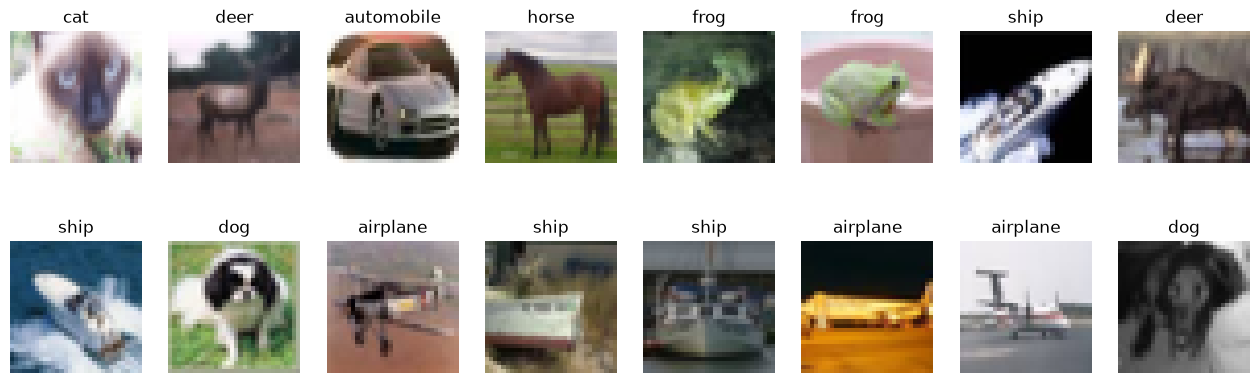

In [25]:
images, label = next(iter(train_loader)) 
print(f"Images Tensor size: {images.shape}")    # [Batch size, channel,width,height]
print(f"Label Tensor size: {label.shape}")      # [Batch size]

%pip install matplotlib
import matplotlib.pyplot as plt

classes = train_dataset.classes
fig, axes = plt.subplots(2, 8, figsize=(16, 5))
for img, label, ax in zip(images, label, axes.flat):
    ax.imshow(img.permute(1, 2, 0))  
    ax.set_title(classes[label])
    ax.axis("off")
plt.show()


# **Task 4: Dataset Augmentation**

In [26]:
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4, padding_mode="reflect"),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)),
    transforms.RandomErasing(p=0.25),   # optional, extra regularization
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)),
])
train_dataset.transform = train_transform
test_dataset.transform = test_transform

train_loader = DataLoader(
    dataset=train_dataset,
    batch_size= 128,
    shuffle= True,
    num_workers= 4,
    pin_memory=True, 
    persistent_workers=True
)

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=4,
    pin_memory=True, 
    persistent_workers=True
)

# **Task 5: Training and Tuning**

In [27]:
import torch.optim as optim
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

In [28]:
def fit(model, train_loader, test_loader, epochs, optimizer, criterion, scheduler):
    history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
    for epoch in range(epochs):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer, criterion, scheduler)
        te_loss, te_acc = evaluate(model, test_loader, criterion)
        history["train_loss"].append(tr_loss); history["train_acc"].append(tr_acc)
        history["test_loss"].append(te_loss);  history["test_acc"].append(te_acc)
        print(f"Epoch {epoch+1}/{epochs} | train loss {tr_loss:.4f} | "
              f"test loss {te_loss:.4f} | test acc {te_acc:.4f}")
    return history


In [29]:
def plot_history(history, title=""):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(epochs, history["train_loss"], label="train loss")
    ax1.plot(epochs, history["test_loss"], label="test loss")
    ax1.set_xlabel("epoch"); ax1.set_ylabel("loss"); ax1.legend()
    ax2.plot(epochs, history["test_acc"], label="test acc")
    ax2.set_xlabel("epoch"); ax2.set_ylabel("accuracy"); ax2.legend()
    fig.suptitle(title)
    plt.show()


Epoch 1/40 | train loss 1.6211 | test loss 1.4296 | test acc 0.5786


Epoch 2/40 | train loss 1.3502 | test loss 1.3027 | test acc 0.6641


Epoch 3/40 | train loss 1.2454 | test loss 1.2501 | test acc 0.6812


Epoch 4/40 | train loss 1.1709 | test loss 1.0843 | test acc 0.7686


Epoch 5/40 | train loss 1.1181 | test loss 1.1388 | test acc 0.7344


Epoch 6/40 | train loss 1.0725 | test loss 1.0636 | test acc 0.7713


... (30 outputs left out)

Epoch 37/40 | train loss 0.6910 | test loss 0.7171 | test acc 0.9247


Epoch 38/40 | train loss 0.6780 | test loss 0.7114 | test acc 0.9266


Epoch 39/40 | train loss 0.6676 | test loss 0.7080 | test acc 0.9282


Epoch 40/40 | train loss 0.6616 | test loss 0.7073 | test acc 0.9285


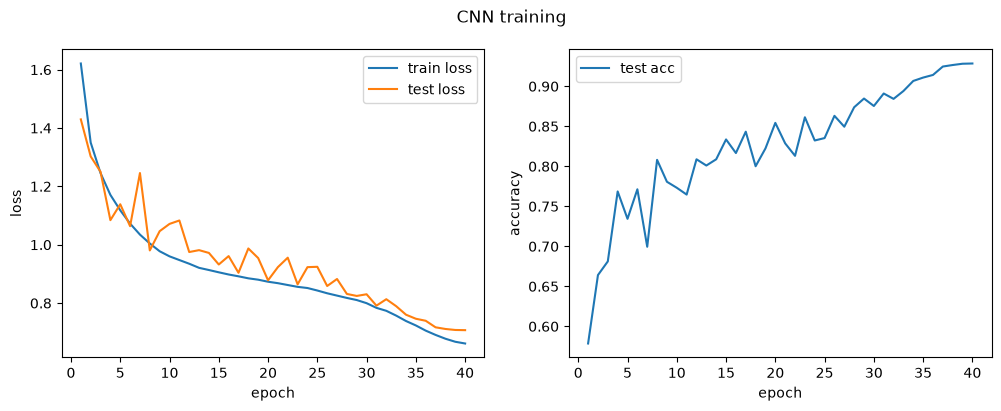

In [30]:
EPOCHS = 40
model = CNN().to(device)
optimizer = optim.SGD(model.parameters(), lr=0.1, momentum=0.9, nesterov=True, weight_decay=5e-4)
scheduler = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=0.1, epochs=EPOCHS, steps_per_epoch=len(train_loader))
history = fit(model, train_loader, test_loader, EPOCHS, optimizer, criterion, scheduler)
plot_history(history, "CNN training")
